# Лабораторная работа № 2. Градиентное обучение спайковой сети

Обучим свёрточную SNN с нуля на **DVSGesture** — это второй вариант пункта 3 задания.
Сравним три суррогатных градиента и проверим, что меняется при штрафе за спайки.

Ноутбук рассчитан на последовательный запуск с GPU. Полное обучение: четыре эксперимента по 30 эпох.
Короткие проверки ниже работают без датасета. Результаты обучения появятся только после запуска на реальных данных.

Основа архитектуры: [руководство SpikingJelly](https://spikingjelly.readthedocs.io/zh-cn/0.0.0.0.14/activation_based_en/classify_dvsg.html).

## 1. Библиотеки и параметры

In [1]:
%pip install -q spikingjelly==0.0.0.0.14 scikit-learn pandas matplotlib tqdm

Note: you may need to restart the kernel to use updated packages.


In [ ]:
from pathlib import Path
import random
import time
import copy
import ctypes
import importlib.metadata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

nvrtc_path = Path(torch.__file__).resolve().parent.parent / 'nvidia/cu13/lib/libnvrtc-builtins.so.13.0'
if torch.version.cuda and torch.version.cuda.startswith('13.') and nvrtc_path.is_file():
    nvrtc_builtins = ctypes.CDLL(str(nvrtc_path))

from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, Subset, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from IPython.display import display
from spikingjelly.activation_based import layer, neuron, surrogate, functional
from spikingjelly.datasets.dvs128_gesture import DVS128Gesture

SEED = 42
T = 16
CHANNELS = 32
BATCH_SIZE = 8
EPOCHS = 30
LR = 1e-3
SPIKE_LAMBDA = 0.01

# Запуск из корня репозитория или из папки lab2.
LAB_DIR = Path.cwd() / 'lab2' if (Path.cwd() / 'lab2').is_dir() else Path.cwd()
DATA_DIR = LAB_DIR / 'data' / 'DVSGesture'
RESULTS_DIR = LAB_DIR / 'results'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def seed_everything():
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

seed_everything()
print('Устройство:', device)
print('PyTorch:', torch.__version__, '| SpikingJelly:', importlib.metadata.version('spikingjelly'))

Устройство: cuda
PyTorch: 2.11.0+cu130 | SpikingJelly: 0.0.0.0.14


## 2. Нейрон и суррогатный градиент

Для LIF с $\tau=2$, порогом $1$ и сбросом в ноль:

$$u_t=v_{t-1}+\frac{x_t-v_{t-1}}{\tau},\qquad
s_t=H(u_t-1),\qquad v_t=u_t(1-s_t).$$

Производная ступеньки равна нулю почти везде. Поэтому при обратном проходе вместо неё
подставляем гладкую или кусочно-гладкую функцию $g(z)$, где $z=u_t-1$.
Прямой проход по-прежнему выдаёт только 0 и 1.

| Метод | Подставляемая производная | Параметр |
|---|---|---|
| ATan | $\frac{\alpha/2}{1+(\pi\alpha z/2)^2}$ | $\alpha=2$ |
| Sigmoid | $\alpha\sigma(\alpha z)(1-\sigma(\alpha z))$ | $\alpha=4$ |
| PiecewiseQuadratic | $\alpha\max(0,1-\alpha|z|)$ | $\alpha=1$ |

У всех трёх максимум производной равен 1, но различаются ширина и хвосты.
`detach_reset=True` исключает производную спайка из операции сброса мембраны.
Градиент по времени всё равно проходит через состояние нейрона (BPTT).

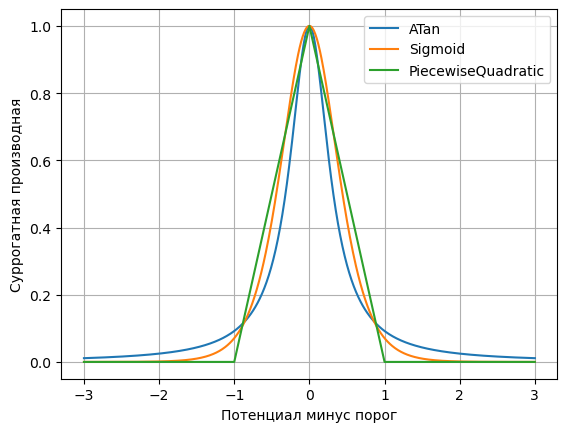

In [3]:
SURROGATES = {
    'ATan': lambda: surrogate.ATan(alpha=2.0),
    'Sigmoid': lambda: surrogate.Sigmoid(alpha=4.0),
    'PiecewiseQuadratic': lambda: surrogate.PiecewiseQuadratic(alpha=1.0),
}

z = torch.linspace(-3, 3, 601, requires_grad=True)
for name, make_surrogate in SURROGATES.items():
    derivative = torch.autograd.grad(make_surrogate()(z).sum(), z)[0]
    plt.plot(z.detach(), derivative, label=name)
plt.xlabel('Потенциал минус порог')
plt.ylabel('Суррогатная производная')
plt.grid()
plt.legend()
plt.show()

## 3. Свёрточная SNN

Вход сети: `[T, batch, 2, 128, 128]`. Пять блоков уменьшают размер до $4\times4$.
За ними идут Linear–LIF–Linear–LIF и голосование: каждые 10 выходных нейронов отвечают за один класс.
Среднее голосование за $T$ шагов даёт 11 оценок классов.

Помимо оценок возвращаем среднюю активность всех LIF-нейронов:

$$r=\frac{\sum_{l,t,b,i}s_{l,t,b,i}}{\sum_l T B N_l},\qquad
L=\operatorname{MSE}(\bar y,\mathrm{onehot}(y))+\lambda r.$$

Большие слои в этом штрафе имеют больший вес. Сумму спайков не отсоединяем от графа,
иначе регуляризация не повлияет на обучение.

In [ ]:
class GestureSNN(nn.Module):
    def __init__(self, gradient='ATan', channels=CHANNELS):
        super().__init__()
        blocks = []
        for i in range(5):
            blocks.extend([
                layer.Conv2d(2 if i == 0 else channels, channels, 3, padding=1, bias=False),
                layer.BatchNorm2d(channels),
                neuron.LIFNode(tau=2.0, surrogate_function=SURROGATES[gradient](), detach_reset=True),
                layer.MaxPool2d(2),
            ])
        blocks.extend([
            layer.Flatten(), layer.Dropout(0.5),
            layer.Linear(channels * 4 * 4, 512),
            neuron.LIFNode(tau=2.0, surrogate_function=SURROGATES[gradient](), detach_reset=True),
            layer.Dropout(0.5), layer.Linear(512, 110),
            neuron.LIFNode(tau=2.0, surrogate_function=SURROGATES[gradient](), detach_reset=True),
            layer.VotingLayer(10),
        ])
        self.layers = nn.Sequential(*blocks)
        functional.set_step_mode(self, 'm')

    def forward(self, frames):
        x = frames
        spike_sum = frames.new_zeros(())
        neuron_steps = 0
        for module in self.layers:
            x = module(x)
            if isinstance(module, neuron.LIFNode):
                spike_sum = spike_sum + x.sum()
                neuron_steps += x.numel()
        return x.mean(0), spike_sum / neuron_steps

## 4. Обучение и валидация

Все запуски используют одинаковые начальные веса, seed и порядок батчей. Dropout включён только при обучении.
После каждого батча сбрасываем мембраны, чтобы независимые записи не влияли друг на друга.
Выбираем лучшую эпоху по validation accuracy; test при выборе модели не используется.

Время обучения включает загрузку батчей, forward, backward и шаг Adam; валидация измеряется отдельно.
Перед замером синхронизируем CUDA. Для сравнения среднего времени эпохи пропускаем первую эпоху
с прогревом. Кривые по времени включают все эпохи. Счётчиков операций во время обучения нет.

In [ ]:
def synchronize():
    if device.type == 'cuda':
        torch.cuda.synchronize()


def run_epoch(model, loader, optimizer=None, spike_lambda=0.0):
    training = optimizer is not None
    model.train(training)
    totals = np.zeros(4)  # MSE, полный loss, accuracy, активность
    samples = 0
    functional.reset_net(model)
    synchronize()
    started = time.perf_counter()
    with torch.set_grad_enabled(training):
        for frames, labels in loader:
            frames = frames.to(device, dtype=torch.float32).transpose(0, 1)
            labels = labels.to(device)
            if training:
                optimizer.zero_grad(set_to_none=True)
            scores, activity = model(frames)
            mse = F.mse_loss(scores, F.one_hot(labels, 11).float())
            loss = mse + spike_lambda * activity
            if not torch.isfinite(loss):
                raise RuntimeError('Loss стал NaN или inf')
            if training:
                loss.backward()
                optimizer.step()
            size = labels.numel()
            totals += np.array([mse.item(), loss.item(),
                                (scores.argmax(1) == labels).float().mean().item(),
                                activity.item()]) * size
            samples += size
            functional.reset_net(model)
    synchronize()
    metrics = dict(zip(['mse', 'loss', 'accuracy', 'activity'], totals / samples))
    metrics['seconds'] = time.perf_counter() - started
    return metrics


def train_experiment(name, gradient, spike_lambda, initial_state, train_set, val_loader):
    seed_everything()
    model = GestureSNN(gradient).to(device)
    model.load_state_dict(initial_state)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True,
                              num_workers=0, generator=torch.Generator().manual_seed(SEED))
    best_accuracy = -1.0
    history = []
    for epoch in range(1, EPOCHS + 1):
        train = run_epoch(model, train_loader, optimizer, spike_lambda)
        val = run_epoch(model, val_loader, spike_lambda=spike_lambda)
        row = {'epoch': epoch, **{f'train_{k}': v for k, v in train.items()},
               **{f'val_{k}': v for k, v in val.items()}}
        history.append(row)
        if val['accuracy'] > best_accuracy:
            best_accuracy = val['accuracy']
            torch.save({'state_dict': model.state_dict(), 'epoch': epoch,
                        'gradient': gradient, 'spike_lambda': spike_lambda,
                        'T': T, 'channels': CHANNELS, 'seed': SEED}, RESULTS_DIR / f'{name}.pt')
        pd.DataFrame(history).to_csv(RESULTS_DIR / f'{name}_history.csv', index=False)
        print(f"{name}: {epoch:02d}/{EPOCHS}, train={train['accuracy']:.3f}, "
              f"val={val['accuracy']:.3f}, {train['seconds']:.1f} с")
    return pd.DataFrame(history)

## 5. Что считаем в MAC, AC и спайках

Метрики относятся к **одному примеру при инференсе**, с выключенным dropout.

- **MAC:** первая свёртка получает числовые количества событий. Считаем плотную стоимость
  $T H_{out}W_{out}C_{out}C_{in}K_hK_w$, включая позиции padding.
- **AC:** остальные Conv/Linear получают бинарные спайки. Каждый активный вход добавляет вес
  во все связанные выходы. У Conv учитываем границы и stride, у Linear число AC равно числу
  входных спайков, умноженному на число выходов. MaxPool сохраняет бинарность.
- **Спайки:** сумма выходов всех LIF-слоёв до pooling и голосования. Один спайк может вызвать много AC.
- **Задержка:** $T=16$ шагов модели, не тактов GPU и не миллисекунд. При разбиении по числу событий
  длительность одного шага в исходной записи непостоянна.

Это оценка синаптической стоимости событийного исполнения, а не счётчик инструкций GPU:
PyTorch выполняет плотные операции даже для нулевых спайков. Не учитываем bias, BatchNorm,
pooling, голосование, обновление мембраны, передачу данных и обучение. Поэтому по этим числам
нельзя напрямую вычислить энергопотребление или ускорение оборудования.

In [6]:
def synaptic_ac(module, x):
    # Вызывается только при инференсе: входы этих слоёв бинарные.
    if isinstance(module, nn.Linear):
        return x.sum(dtype=torch.float64).item() * module.out_features
    x = x.flatten(0, 1)  # [T, B, C, H, W] -> [T*B, C, H, W]
    kernel = x.new_ones(1, 1, *module.kernel_size)
    # Сумма событий в каждом окне; у каждого входного канала Cout/groups связей.
    windows = F.conv2d(x.sum(1, keepdim=True), kernel, stride=module.stride,
                       padding=module.padding, dilation=module.dilation)
    return windows.sum(dtype=torch.float64).item() * (module.out_channels // module.groups)


@torch.no_grad()
def evaluate_cost(model, loader):
    model.eval()
    functional.reset_net(model)
    totals = {'MAC': 0.0, 'AC': 0.0, 'spikes': 0.0, 'neuron_steps': 0}
    layer_spikes = {}
    first_conv = next(m for m in model.modules() if isinstance(m, nn.Conv2d))

    def count_operations(module, inputs, output):
        if module is first_conv:
            fan_in = module.weight[0].numel()
            totals['MAC'] += output.numel() * fan_in
        else:
            totals['AC'] += synaptic_ac(module, inputs[0])

    def spike_hook(name):
        def count(module, inputs, output):
            amount = output.sum(dtype=torch.float64).item()
            totals['spikes'] += amount
            totals['neuron_steps'] += output.numel()
            layer_spikes[name] = layer_spikes.get(name, 0.0) + amount
        return count

    handles = []
    for name, module in model.named_modules():
        if isinstance(module, (nn.Conv2d, nn.Linear)):
            handles.append(module.register_forward_hook(count_operations))
        if isinstance(module, neuron.LIFNode):
            handles.append(module.register_forward_hook(spike_hook(name)))
    targets, predictions = [], []
    latency = None
    try:
        for frames, labels in loader:
            if latency is None:
                latency = frames.shape[1]
            assert frames.shape[1] == latency
            scores, _ = model(frames.to(device, dtype=torch.float32).transpose(0, 1))
            targets.extend(labels.tolist())
            predictions.extend(scores.argmax(1).cpu().tolist())
            functional.reset_net(model)
    finally:
        for handle in handles:
            handle.remove()
        functional.reset_net(model)
    n = len(targets)
    metrics = {key + '_per_sample': totals[key] / n for key in ['MAC', 'AC', 'spikes']}
    metrics.update(accuracy=np.mean(np.array(targets) == predictions),
                   activity=totals['spikes'] / totals['neuron_steps'], T=latency)
    return metrics, {k: v / n for k, v in layer_spikes.items()}, targets, predictions

## 6. Короткие проверки без DVSGesture

Проверяем ручной пример AC, размерности, конечные градиенты, воспроизводимость после сброса
и наличие градиента у штрафа. Затем для каждого опыта делаем один шаг Adam и оценку на
синтетических кадрах. Это проверка кода, а не качества распознавания жестов.

In [7]:
EXPERIMENTS = [
    ('atan', 'ATan', 0.0),
    ('sigmoid', 'Sigmoid', 0.0),
    ('piecewise', 'PiecewiseQuadratic', 0.0),
    ('atan_regularized', 'ATan', SPIKE_LAMBDA),
]


def self_check():
    conv = layer.Conv2d(1, 2, 3, padding=1, bias=False, step_mode='m')
    x = torch.zeros(1, 1, 1, 3, 3)
    x[0, 0, 0, 0, 0] = x[0, 0, 0, 1, 1] = 1
    assert synaptic_ac(conv, x) == (4 + 9) * 2
    assert conv(x).numel() * conv.weight[0].numel() == 162
    assert synaptic_ac(conv, torch.zeros_like(x)) == 0
    linear = layer.Linear(4, 3, step_mode='m')
    assert synaptic_ac(linear, torch.tensor([[[1., 0., 1., 0.]]])) == 6

    seed_everything()
    frames = torch.rand(2, 2, 2, 128, 128) * 3
    labels = torch.tensor([0, 1])
    loader = DataLoader(TensorDataset(frames, labels), batch_size=2)
    for name, gradient, coefficient in EXPERIMENTS:
        model = GestureSNN(gradient, channels=2).to(device)
        optimizer = torch.optim.Adam(model.parameters(), lr=LR)
        train = run_epoch(model, loader, optimizer, coefficient)
        assert np.isfinite(train['loss'])
        assert all(torch.isfinite(p.grad).all() for p in model.parameters() if p.grad is not None)
        assert model.layers[0].weight.grad.abs().sum() > 0
        metrics, _, _, _ = evaluate_cost(model, loader)
        assert metrics['MAC_per_sample'] > 0 and metrics['AC_per_sample'] >= 0
        assert metrics['T'] == 2
        inputs = frames.to(device).transpose(0, 1)
        first, _ = model(inputs)
        functional.reset_net(model)
        second, _ = model(inputs)
        assert first.shape == (2, 11) and torch.allclose(first, second)
        functional.reset_net(model)

        model.train()
        _, activity = model(inputs)
        penalty_gradient = torch.autograd.grad(SPIKE_LAMBDA * activity, model.layers[0].weight)[0]
        assert torch.isfinite(penalty_gradient).all() and penalty_gradient.abs().sum() > 0
        functional.reset_net(model)
    print('Проверки пройдены: 4 конфигурации, backward, reset, MAC/AC и градиент штрафа.')

self_check()

Проверки пройдены: 4 конфигурации, backward, reset, MAC/AC и градиент штрафа.


## 7. Данные DVSGesture

В SpikingJelly 0.0.0.0.14 автоматическое скачивание этого датасета не поддерживается.
Скачайте `DvsGesture.tar.gz`, `gesture_mapping.csv`, `LICENSE.txt` и `README.txt`
из [каталога IBM](https://ibm.ent.box.com/s/3hiq58ww1pbbjrinh367ykfdf60xsfm8/folder/50167556794)
в `lab2/data/DVSGesture/download/`. Архив самостоятельно распаковывать не нужно.
Первое создание датасета проверяет файлы, распаковывает события и сохраняет кадры; для этого нужны время и место на диске.

Представление: 16 последовательных групп с примерно одинаковым числом событий.
В каждом пикселе суммируем события отдельно для двух полярностей: форма `[T, 2, 128, 128]`.
Кадры содержат количества событий, а не бинарные значения; дополнительное пуассоновское кодирование не нужно.

Официальный test оставляем для итоговой оценки. Из train выделяем 15% записей в validation
стратифицированно по классам. Это разбиение по записям, а не по участникам; независимость участников
обеспечивается официальным train/test, но не внутренней валидацией.

The [/home/homa/neuromorphic-computing/lab2/data/DVSGesture/download] directory for saving downloaded files already exists, check files...
Mkdir [/home/homa/neuromorphic-computing/lab2/data/DVSGesture/extract].
Extract [/home/homa/neuromorphic-computing/lab2/data/DVSGesture/download/DvsGesture.tar.gz] to [/home/homa/neuromorphic-computing/lab2/data/DVSGesture/extract].
Mkdir [/home/homa/neuromorphic-computing/lab2/data/DVSGesture/events_np].
Start to convert the origin data from [/home/homa/neuromorphic-computing/lab2/data/DVSGesture/extract] to [/home/homa/neuromorphic-computing/lab2/data/DVSGesture/events_np] in np.ndarray format.
Mkdir [('/home/homa/neuromorphic-computing/lab2/data/DVSGesture/events_np/train', '/home/homa/neuromorphic-computing/lab2/data/DVSGesture/events_np/test').
Mkdir ['8', '1', '4', '9', '5', '2', '10', '3', '7', '0', '6'] in [/home/homa/neuromorphic-computing/lab2/data/DVSGesture/events_np/train] and ['8', '1', '4', '9', '5', '2', '10', '3', '7', '0', '6'] in 

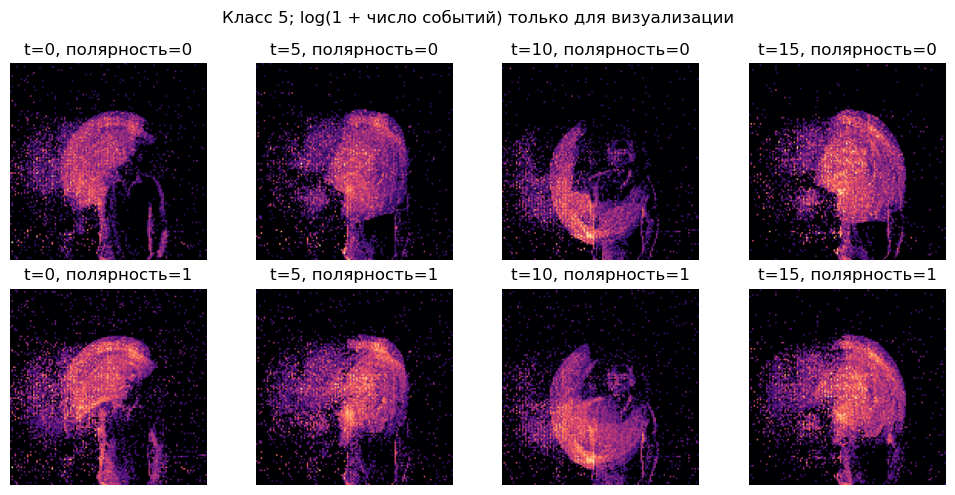

In [11]:
if not (DATA_DIR / 'events_np').is_dir():
    missing = [name for name, _, _ in DVS128Gesture.resource_url_md5()
               if not (DATA_DIR / 'download' / name).is_file()]
    if missing:
        raise FileNotFoundError(f"Скачайте {', '.join(missing)} в {DATA_DIR / 'download'}")

full_train = DVS128Gesture(str(DATA_DIR), train=True, data_type='frame',
                           frames_number=T, split_by='number')
test_set = DVS128Gesture(str(DATA_DIR), train=False, data_type='frame',
                         frames_number=T, split_by='number')
train_idx, val_idx = train_test_split(
    np.arange(len(full_train)), test_size=0.15, random_state=SEED,
    stratify=full_train.targets,
)
train_set, val_set = Subset(full_train, train_idx), Subset(full_train, val_idx)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
assert not set(train_idx) & set(val_idx)
np.savez(RESULTS_DIR / 'split.npz', train=train_idx, validation=val_idx)
print(f'Train: {len(train_set)}, validation: {len(val_set)}, test: {len(test_set)}')

frames, label = train_set[0]
assert frames.shape == (T, 2, 128, 128)
assert np.isfinite(frames).all() and (frames >= 0).all()
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for column, t in enumerate(np.linspace(0, T - 1, 4, dtype=int)):
    for polarity in range(2):
        axes[polarity, column].imshow(np.log1p(frames[t, polarity]), cmap='magma')
        axes[polarity, column].set_title(f't={t}, полярность={polarity}')
        axes[polarity, column].axis('off')
fig.suptitle(f'Класс {label}; log(1 + число событий) только для визуализации')
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'frames.png', dpi=150)
plt.show()

## 8. Четыре эксперимента

Число эпох и batch size меняйте в начале ноутбука одинаково для всех опытов.
При нехватке памяти уменьшите `BATCH_SIZE` и перезапустите все четыре опыта.
Для проверки на реальных данных можно временно поставить `EPOCHS=1`, но этого недостаточно для выводов.

Сначала сравниваем градиенты без регуляризации. Затем повторяем ATan с фиксированным штрафом 0.01.
Коэффициент не подбираем по test. Один seed позволяет сделать учебное сравнение,
но не установить статистическую значимость различий.

In [ ]:
seed_everything()
initial_model = GestureSNN()
initial_state = copy.deepcopy(initial_model.state_dict())
del initial_model
histories = {}
for name, gradient, coefficient in EXPERIMENTS:
    histories[name] = train_experiment(name, gradient, coefficient, initial_state, train_set, val_loader)

atan: 01/30, train=0.315, val=0.497, 20.7 с
atan: 02/30, train=0.585, val=0.644, 21.9 с
atan: 03/30, train=0.631, val=0.644, 21.0 с
atan: 04/30, train=0.667, val=0.695, 19.5 с
atan: 05/30, train=0.701, val=0.678, 21.1 с
atan: 06/30, train=0.731, val=0.661, 22.5 с
atan: 07/30, train=0.747, val=0.678, 19.8 с
atan: 08/30, train=0.748, val=0.695, 20.5 с
atan: 09/30, train=0.785, val=0.740, 22.7 с
atan: 10/30, train=0.782, val=0.729, 19.4 с
atan: 11/30, train=0.782, val=0.740, 19.2 с
atan: 12/30, train=0.810, val=0.751, 19.2 с
atan: 13/30, train=0.815, val=0.751, 19.6 с
atan: 14/30, train=0.835, val=0.785, 19.3 с
atan: 15/30, train=0.838, val=0.740, 20.1 с
atan: 16/30, train=0.830, val=0.695, 19.9 с
atan: 17/30, train=0.841, val=0.785, 19.8 с
atan: 18/30, train=0.860, val=0.808, 19.4 с
atan: 19/30, train=0.846, val=0.797, 19.3 с
atan: 20/30, train=0.871, val=0.791, 19.4 с
atan: 21/30, train=0.864, val=0.797, 19.5 с
atan: 22/30, train=0.870, val=0.763, 19.7 с
atan: 23/30, train=0.878, val=0.

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for name, _, _ in EXPERIMENTS:
    history = histories[name]
    axes[0].plot(history.epoch, history.train_mse, label=name)
    axes[1].plot(history.epoch, history.val_accuracy, label=name)
    axes[2].plot(history.train_seconds.cumsum(), history.val_accuracy, label=name)
for ax, xlabel, ylabel in zip(axes, ['Эпоха', 'Эпоха', 'Время обучения, с'],
                            ['Train MSE', 'Validation accuracy', 'Validation accuracy']):
    ax.set(xlabel=xlabel, ylabel=ylabel)
    ax.grid()
    ax.legend()
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'learning_curves.png', dpi=150)
plt.show()

## 9. Итоговая оценка

Один проход test для лучшей по validation эпохи каждого опыта.
Профилирование выполняется отдельно от обучения, поэтому не искажает измеренное время эпохи.
В таблице время до лучшей эпохи — сумма времени обучения до выбранного checkpoint, без валидации.

In [ ]:
rows, spike_rows = [], []
for name, gradient, coefficient in EXPERIMENTS:
    checkpoint = torch.load(RESULTS_DIR / f'{name}.pt', map_location='cpu', weights_only=True)
    model = GestureSNN(gradient).to(device)
    model.load_state_dict(checkpoint['state_dict'])
    metrics, spikes_by_layer, targets, predictions = evaluate_cost(model, test_loader)
    history = histories[name]
    steady_times = history.train_seconds.iloc[1:] if len(history) > 1 else history.train_seconds
    rows.append({'experiment': name, 'lambda': coefficient,
                 'best_epoch': checkpoint['epoch'],
                 'best_val_accuracy': history.val_accuracy.max(),
                 'mean_train_epoch_s': steady_times.mean(),
                 'train_to_best_s': history.train_seconds.iloc[:checkpoint['epoch']].sum(),
                 **metrics})
    spike_rows.extend({'experiment': name, 'layer': key, 'spikes_per_sample': value}
                      for key, value in spikes_by_layer.items())
    if name == 'atan':
        cm = confusion_matrix(targets, predictions, labels=np.arange(11))
        ConfusionMatrixDisplay(cm, display_labels=np.arange(11)).plot(cmap='Blues')
        plt.title('ATan: test, номера классов 0–10')
        plt.tight_layout()
        plt.savefig(RESULTS_DIR / 'confusion_matrix.png', dpi=150)
        plt.show()
    del model

results = pd.DataFrame(rows).set_index('experiment')
results.to_csv(RESULTS_DIR / 'results.csv')
spike_table = pd.DataFrame(spike_rows)
spike_table.to_csv(RESULTS_DIR / 'spikes_by_layer.csv', index=False)
display(results.round(4))
display(spike_table.pivot(index='layer', columns='experiment', values='spikes_per_sample').round(1))

In [ ]:
comparison = results.loc[['atan', 'atan_regularized'], ['accuracy', 'spikes_per_sample', 'AC_per_sample']]
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, metric in zip(axes, comparison.columns):
    comparison[metric].plot.bar(ax=ax, rot=15, title=metric, color=['steelblue', 'coral'])
    ax.set_xlabel('')
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'regularization.png', dpi=150)
plt.show()

baseline, regularized = results.loc['atan'], results.loc['atan_regularized']
print(f"Изменение test accuracy при штрафе: {(regularized.accuracy - baseline.accuracy) * 100:+.2f} п.п.")
for metric in ['spikes_per_sample', 'AC_per_sample']:
    if baseline[metric] > 0:
        print(f'{metric}: изменение {100 * (regularized[metric] / baseline[metric] - 1):+.1f}%')
    else:
        print(f'{metric}: у базовой модели 0, относительное изменение не определено')
print('Самый быстрый градиент по среднему времени эпохи:',
      results.loc[['atan', 'sigmoid', 'piecewise'], 'mean_train_epoch_s'].idxmin())

## 10. Обсуждение результатов

Для test использовалась лучшая по валидации эпоха каждого запуска.

| Вариант | Лучшая эпоха | Validation, % | Test, % | Секунд на эпоху | Спайки, тыс./пример | AC, млн/пример |
|---|---:|---:|---:|---:|---:|---:|
| ATan | 28 | 85,31 | 80,90 | 20,02 | 195,93 | 32,09 |
| Sigmoid | 24 | 83,62 | 80,90 | 19,88 | 214,83 | 34,43 |
| PiecewiseQuadratic | 29 | 85,88 | 87,50 | 19,85 | 222,85 | 35,62 |
| ATan + регуляризация | 28 | 84,75 | 80,90 | 19,81 | 114,67 | 18,14 |

Лучше всего сработал **PiecewiseQuadratic: 87,5% на test**, против 80,9% у ATan и Sigmoid. Время эпохи почти одинаковое — около 20 секунд. По скорости достижения 80% на валидации PiecewiseQuadratic также оказался первым:

| Вариант | Первое достижение 80% на валидации | Время обучения до этой эпохи, с |
|---|---:|---:|
| ATan | 18 | 365,7 |
| Sigmoid | 24 | 476,0 |
| PiecewiseQuadratic | 17 | 335,7 |
| ATan + регуляризация | 20 | 397,1 |

Это первое достижение порога: на следующих эпохах точность могла снова снижаться. Время указано без валидации.

Регуляризация ATan с $\lambda=0{,}01$ снизила число спайков на **41,5%**, а AC — на **43,5%**. Точность на test осталась **80,9%**. Основное сокращение спайков пришлось на первые слои; на выходе их число почти не изменилось.

Во всех опытах **151 млн MAC на пример** и **16 временных шагов**. Стоимость первой свёртки не меняется: она получает числовые кадры. Снижение AC относится к последующим слоям и не означает такого же ускорения на GPU, где PyTorch выполняет плотные операции.

По точности здесь выигрывает PiecewiseQuadratic. Если достаточно 80,9%, выгоднее ATan с регуляризацией: меньше спайков и AC при той же точности. Это результат одного запуска с фиксированным seed; устойчивость различий мы не проверяли.